In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import numpy.ma as ma
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import xarray as xr
import pandas as pd



In [2]:
domainM='GRq'; nx=ny=10

In [3]:
## Model MAR
domain='GRc'
sourceDataGrid='/home/santolam/'
fileName_grM='NST.2000.01.01.00.GRc.nc'
dsM= xr.open_dataset(sourceDataGrid+fileName_grM)
LONS=dsM.LON[ny:-ny,nx:-nx].values;LATS=dsM.LAT[ny:-ny,nx:-nx].values
dsSH=dsM.SH[ny:-ny,nx:-nx];dsICE=dsM.ICE[ny:-ny,nx:-nx]

dsSH=dsSH.rename({'y': 'Y','x':'X'})

In [4]:
#ds_TF=ds_SF+ds_RF

In [5]:
####
##Donnes meteo
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/glacioclim/donnees_precip/'
#
#Precipitation_Khare_corrected_Nov2016_Nov2023_final.xlsx
#Precipitation_Pyramid_Pheriche_corrected_Apr2016_Nov2023_final.xlsx
#Precipitation_Pyramid_Pheriche_corrected_Dec2012_Apr2016_final.xlsx

In [6]:
#https://github.com/Andeol-ramb/MAR_HMA_GLACIOCLIM_Comparisons/blob/main/Sensitivity_Test_MAR/Sensitivity_Test_Pyramide_Precip.ipynb
####
## Opening Pheriche+Khare
####

sourceDataSta=sourceData#'/Users/santolam/Data/glacioclim/donnees_precip/'
path1 =sourceDataSta+"/Precipitation_Pyramid_Pheriche_corrected_Dec2012_Apr2016_final.xlsx"
xl_data1=pd.ExcelFile(path1)

dfs1= {sheet_name: xl_data1.parse(sheet_name) 
       for sheet_name in xl_data1.sheet_names}

DataPyramid_Pheriche12_16=dfs1['Precip_data_Dec12_Apr16']

NameVarsPP12_16=['TimeY','RRYhourly','RRYcumul','TimeH','RRHhourly','RRHcumul']
UnitVarsPP16_23=['data/hour','mm','mm','data/hour','mm','mm',]

dfile1P12_16= pd.DataFrame(data=DataPyramid_Pheriche12_16.loc[10:])
df1P12_16=pd.DataFrame(dfile1P12_16.values, columns=NameVarsPP12_16)

df1P12_16['TimeY'] = df1P12_16['TimeY'].dt.round('h')

path =sourceDataSta+"/Precipitation_Pyramid_Pheriche_corrected_Apr2016_Nov2023_final.xlsx"
xl_data=pd.ExcelFile(path)

dfs = {sheet_name: xl_data.parse(sheet_name) 
       for sheet_name in xl_data.sheet_names}
DataPyramid_Pheriche16_23=dfs['Precip_data_Apr16_Nov23']

NameVarsPP16_23=['TimeY','TairY','uY','RHY','WMOphaseY','RRYhourly','RRYcumul','TimeH','TairH','uH','RHh','WMOphaseH','RRHhourly','RRHcumul']
UnitVarsPP16_23=['data/hour','(°C)','(ms-1)','(%)','mm','mm','data/hour','(°C)','(ms-1)','(%)','mm','mm',]

dfile1P16_23= pd.DataFrame(data=DataPyramid_Pheriche16_23.loc[10:57630]) #3399 marche, Toujours la même taille jusque 3399 puis toujours lenght var=t-1 par la suite 
#CHANGEMENT DANS TIME:3389 	2016-09-15 17:59:59.!999! / 2016-09-15 18:59:59.!998! 
#donc erreur à chaque changement de décimale, corriger cette data avant tout autre chose


dfile2P16_23=pd.DataFrame(data=DataPyramid_Pheriche16_23.loc[57632:]) 
df1P16_23=pd.DataFrame(dfile1P16_23.values, columns=NameVarsPP16_23)
df2P16_23=pd.DataFrame(dfile2P16_23.values, columns=NameVarsPP16_23)
df1P16_23['TimeY'] = df1P16_23['TimeY'].dt.round('h')
df2P16_23['TimeY'] = df2P16_23['TimeY'].dt.round('30min')

#Definition d'une fréquence permettant par la suite le traitement avec des Xarray
def NewTime(df, NameVar, values, freq):
    time = pd.to_datetime(df['TimeY'].values)
    ds = xr.Dataset({NameVar: ("time", np.asarray(values))}, coords={"time": time})
    return ds
# Time step: 1h

RR1_PY=[float(thing) for thing in df1P12_16['RRYhourly'].values]
RRY1_PY = [float(thing) for thing in df1P16_23['RRYhourly'].values]
dsY1_PY = NewTime(df1P16_23, 'RRYhourly', RRY1_PY, '1h')
dsRR1_PY= NewTime(df1P12_16, 'RRYhourly', RR1_PY, '1h')

# Time step : 30 min 
RRY2_PY = [float(thing) for thing in df2P16_23['RRYhourly'].values]
dsY2_PY = NewTime(df2P16_23, 'RRYhourly', RRY2_PY, '30min')
RR_PY = xr.concat([dsRR1_PY,dsY1_PY, dsY2_PY], dim='time')


RR1_PH=[float(thing) for thing in df1P12_16['RRHhourly'].values]
RRY1_PH = [float(thing) for thing in df1P16_23['RRHhourly'].values]
dsY1_PH = NewTime(df1P16_23, 'RRHhourly', RRY1_PH, '1h')
dsRR1_PH= NewTime(df1P12_16, 'RRHhourly', RR1_PH, '1h')

# Time step : 30 min 
RRY2_PH = [float(thing) for thing in df2P16_23['RRHhourly'].values]
dsY2_PH = NewTime(df2P16_23, 'RRHhourly', RRY2_PH, '30min')
RR_PH = xr.concat([dsRR1_PH,dsY1_PH, dsY2_PH], dim='time')

#####
#
#Khare
#
#####
fileName_KH='Precipitation_Khare_corrected_Nov2016_Nov2023_final.xlsx'
xl_file_KH = pd.ExcelFile(sourceDataSta+fileName_KH)
print(xl_file_KH)
#
dfs_KH = {sheet_name: xl_file_KH.parse(sheet_name) 
          for sheet_name in xl_file_KH.sheet_names}

NameVars_KH=['Time','Tair' ,'u' ,'RH', 'Phase_WMO','RR_WMO_Half-hourly_values','RR_WMO_Khare_cumulated']
UnitVars_KH=['time','(°C)','(ms-1)','(%)','phase','mm w.e.','mm w.e.']

##Define new DataFrame and changing name of columns
dfile_KH = pd.DataFrame(data=dfs_KH["Precip_data_Nov16_Nov23"].loc[8:])
df_KH=pd.DataFrame(dfile_KH.values, columns=NameVars_KH)

path =sourceDataSta+fileName_KH
xl_data=pd.ExcelFile(path)
dfs = {sheet_name: xl_data.parse(sheet_name) 
       for sheet_name in xl_data.sheet_names}
DataKhare16_23=dfs['Precip_data_Nov16_Nov23']
NameVarsPP16_23=['Time','Tair','u','RH','WMOphase','RRhourly','RRcumul']
UnitVarsPP16_23=['data/hour','(°C)','(ms-1)','(%)','mm','mm']
dfileP16_23= pd.DataFrame(data=DataKhare16_23.loc[10:])
dfP16_23=pd.DataFrame(dfileP16_23.values, columns=NameVarsPP16_23)

RR_KH=[float(i) for i in dfP16_23.RRhourly.values] 
def NewTime(df, NameVar, values, freq):
    time = pd.to_datetime(df['Time'].values)
    ds = xr.Dataset({NameVar: ("time", np.asarray(values))}, coords={"time": time})
    return ds
RR_KH=NewTime(dfP16_23,'RRhourly',RR_KH,'30min')
#RR=RR.sel(time=slice('2016'))


rr_hourly_PY=RR_PY.resample(time='1H').sum()
#rr_hourly_PY=RR_PY.RRYhourly

rr_hourly_PH=RR_PH.resample(time='1H').sum()
#rr_hourly_PH=RR_PH.RRHhourly

rr_hourly_KH=RR_KH.resample(time='1H').sum()
#rr_hourly_KH=RR_KH.RRhourly

idatePY = str(rr_hourly_PY.time[0].values)[:10]
fdatePY = str(rr_hourly_PY.time[-1].values)[:10]
idatePH = str(rr_hourly_PH.time[0].values)[:10]
fdatePH = str(rr_hourly_PH.time[-1].values)[:10]
idateKH = str(rr_hourly_KH.time[0].values)[:10]
fdateKH = str(rr_hourly_KH.time[-1].values)[:10]


In [7]:
rr_hourly_KH.time

<xarray.DataArray 'time' (time: 61153)>
array(['2016-11-25T11:00:00.000000000', '2016-11-25T12:00:00.000000000',
       '2016-11-25T13:00:00.000000000', ..., '2023-11-17T09:00:00.000000000',
       '2023-11-17T10:00:00.000000000', '2023-11-17T11:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 2016-11-25T11:00:00 ... 2023-11-17T11:00:00

In [8]:
#print(rr_hourly_KH)

In [9]:
###
## PYRAMID Salerno
### 

In [10]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/PYRAMID_NETWORK_DATA_v3/'

file_AWS0='AWS0_Z5035_Lvl1.csv'
file_AWS1='AWS1_Z5035_Lvl1.csv'
file_AWS2='AWS2_Z4260_Lvl1.csv'
file_AWS3='AWS3_Z2660_Lvl1.csv'
file_AWS4='AWS4_Z5600_Lvl1.csv'
file_AWS5='AWS5_Z3570_Lvl1.csv'
file_AWSSC='AWSSC_Z7986_Lvl1.csv'
file_CNG='CNG_SNP_Z5700_Lvl1.csv'
file_mon_Pyr='Pyramid_Z5035_lvl2.csv'

# Store filenames in a dictionary for easy looping
files = {
    'AWS0': file_AWS0,
    'AWS1': file_AWS1,
    'AWS2': file_AWS2,
    'AWS3': file_AWS3,
    'AWS4': file_AWS4,
    'AWS5': file_AWS5,
    'AWSSC': file_AWSSC,
    'CNG': file_CNG,
    #'Pyramid': file_mon_Pyr
}
dfs = {}
for name, fname in files.items():
    path = os.path.join(sourceData, fname)
    
    # Read semicolon-delimited CSV
    df = pd.read_csv(path, sep=';')
    
    # Combine into datetime
    df['TIMESTAMP'] = pd.to_datetime(dict(
        year=df['year'],
        month=df['month'],
        day=df['day'],
        hour=df['hour']
    ))
    
    # Set datetime index and drop date columns
    df.set_index('TIMESTAMP', inplace=True)
    df.drop(columns=['year', 'month', 'day', 'hour'], inplace=True)
    
    # Replace physically impossible values (< -100) with NaN
    df[df < -100] = np.nan
    
    # Store
    dfs[name] = df
    
# Optional: unpack for direct access
df_AWS0  = dfs['AWS0']
df_AWS1  = dfs['AWS1']
df_AWS2  = dfs['AWS2']
df_AWS3  = dfs['AWS3']
df_AWS4  = dfs['AWS4']
df_AWS5  = dfs['AWS5']
df_AWSSC = dfs['AWSSC']
df_CNG   = dfs['CNG']
#df_Pyr   = dfs['Pyramid']

# Quick check
print(df_AWS0.head())

# Daily total precipitation (sum of hourly rates)
rr_AWS0_hourly = df_AWS0['RR']#.resample('D').sum()
rr_AWS1_hourly = df_AWS1['RR']#.resample('D').sum()
rr_AWS2_hourly = df_AWS2['RR']#.resample('D').sum()
rr_AWS3_hourly = df_AWS3['RR']#.resample('D').sum()
rr_AWS4_hourly = df_AWS4['RR']#.resample('D').sum()
rr_AWS5_hourly = df_AWS5['RR']#.resample('D').sum()


                       AT   RR     AP    RH    WS  WD
TIMESTAMP                                            
1994-01-01 02:00:00 -11.9  0.0  551.4  25.0  0.00 NaN
1994-01-01 04:00:00 -13.2  0.0  551.0  23.0  0.00 NaN
1994-01-01 06:00:00 -10.5  0.0  551.1  10.0  0.26 NaN
1994-01-01 08:00:00 -10.9  0.0  551.9  17.0  0.00 NaN
1994-01-01 10:00:00  -7.1  0.0  553.1  17.0  5.58 NaN


In [11]:
rr_AWS0_hourly

TIMESTAMP
1994-01-01 02:00:00    0.0
1994-01-01 04:00:00    0.0
1994-01-01 06:00:00    0.0
1994-01-01 08:00:00    0.0
1994-01-01 10:00:00    0.0
                      ... 
2005-12-31 14:00:00    NaN
2005-12-31 16:00:00    NaN
2005-12-31 18:00:00    NaN
2005-12-31 20:00:00    NaN
2005-12-31 22:00:00    NaN
Name: RR, Length: 52595, dtype: float64

In [12]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/nat_geo_stations_everest/'
#sourceData='/Users/santolam/Desktop/nat_geo_stations_everest/'
##
file_bc='Base_Camp_20230630.csv'
file_c2='Camp2_20230630.csv'
file_phort='Phortse_20230630.csv'
file_bish='Bishop_Rock_20230630.csv'
file_sc='South_Col_20230630.csv'

df_bc = pd.read_csv(os.path.join(sourceData, file_bc), parse_dates=['TIMESTAMP'])
df_c2 = pd.read_csv(os.path.join(sourceData, file_c2), parse_dates=['TIMESTAMP'])
df_phort = pd.read_csv(os.path.join(sourceData, file_phort), parse_dates=['TIMESTAMP'])
df_bish = pd.read_csv(os.path.join(sourceData, file_bish), parse_dates=['TIMESTAMP'])
df_sc = pd.read_csv(os.path.join(sourceData, file_sc), parse_dates=['TIMESTAMP'])

# Optional: set timestamp as index
for df in [df_bc, df_c2, df_phort, df_bish, df_sc]:
    df.set_index('TIMESTAMP', inplace=True)

# Quick check
print(df_bc.head())

rr_bc_hourly = df_bc['PRECIP']#.resample('D').sum()
rr_phort_hourly = df_phort['PRECIP']#.resample('D').sum()


                     T_HMP      RH   PRESS  PRECIP
TIMESTAMP                                         
2019-10-17 13:00:00 -4.078  99.578  536.71     0.0
2019-10-17 14:00:00 -4.282  92.273  537.15     0.0
2019-10-17 15:00:00 -3.584  86.358  537.28     0.0
2019-10-17 16:00:00 -3.458  88.629  537.25     0.0
2019-10-17 17:00:00 -3.966  74.045  537.22     0.0


In [13]:
###Coordinates

In [14]:
import pandas as pd
from pyproj import Transformer

# Define the transformer (UTM Zone 45N → WGS84)
transformer = Transformer.from_crs("epsg:32645", "epsg:4326", always_xy=True)

# --- Coordinates conversions (you already have some precomputed) ---
# MN (Mera North)
eastingMN, northingMN = 489885, 3065938
lon_MN, lat_MN = transformer.transform(eastingMN, northingMN)
elev_MN = 5360

# CH (Changri)
lon_CH, lat_CH, elev_CH = 86.77948450, 27.98336311, 5360

# ML (Merala)
lon_ML, lat_ML, elev_ML = 86.900, 27.735, 5352.008

# KH (Khare)
lon_KH, lat_KH, elev_KH = 86.8776142768303, 27.74424682282522, 4888

# PH (Pheriche)
lon_PH, lat_PH, elev_PH = 86.81972903284355, 27.895048949594884, 4260

# PY (Pyramid)
lon_PY, lat_PY, elev_PY = 86.81296905961787, 27.957821815535848, 5035

# MS (Mera South)
eastingMS, northingMS = 487553.653, 3064704.231
lon_MS, lat_MS = transformer.transform(eastingMS, northingMS)
elev_MS = 5360  # estimated same as MN, if not otherwise specified

# MC (Mera Central)
eastingMC, northingMC = 488409.424, 3066148.049
lon_MC, lat_MC = transformer.transform(eastingMC, northingMC)
elev_MC = 5770

# --- Define metadata list ---
stations_info_glacioclim = [
    {"ID": "MN", "Name": "Mera Naulek", "Lat": lat_MN, "Lon": lon_MN, "Elev_m": elev_MN, "Timestep": "1h"},
    {"ID": "CH", "Name": "Changri", "Lat": lat_CH, "Lon": lon_CH, "Elev_m": elev_CH, "Timestep": "1h"},
    {"ID": "ML", "Name": "Mera La", "Lat": lat_ML, "Lon": lon_ML, "Elev_m": elev_ML, "Timestep": "1h"},
    {"ID": "KH", "Name": "Khare", "Lat": lat_KH, "Lon": lon_KH, "Elev_m": elev_KH, "Timestep": "1h"},
    {"ID": "PH", "Name": "Pheriche", "Lat": lat_PH, "Lon": lon_PH, "Elev_m": elev_PH, "Timestep": "1h"},
    {"ID": "PY", "Name": "Pyramid", "Lat": lat_PY, "Lon": lon_PY, "Elev_m": elev_PY, "Timestep": "1h"},
    {"ID": "MS", "Name": "Mera Summir", "Lat": lat_MS, "Lon": lon_MS, "Elev_m": elev_MS, "Timestep": "1h"},
    {"ID": "MC", "Name": "Mera Camp 5770", "Lat": lat_MC, "Lon": lon_MC, "Elev_m": elev_MC, "Timestep": "1h"},
]

# --- Create DataFrame ---
df_stations_glacioclim = pd.DataFrame(stations_info_glacioclim)

# Display neatly
print(df_stations_glacioclim.to_string(index=False, justify='center', col_space=12))


     ID           Name           Lat          Lon        Elev_m      Timestep  
     MN         Mera Naulek  27.717723    86.897390     5360.000        1h     
     CH             Changri  27.983363    86.779484     5360.000        1h     
     ML             Mera La  27.735000    86.900000     5352.008        1h     
     KH               Khare  27.744247    86.877614     4888.000        1h     
     PH            Pheriche  27.895049    86.819729     4260.000        1h     
     PY             Pyramid  27.957822    86.812969     5035.000        1h     
     MS         Mera Summir  27.706566    86.873753     5360.000        1h     
     MC      Mera Camp 5770  27.719608    86.882420     5770.000        1h     


In [15]:
##
# --- AWS and related station metadata ---

# AWSSC (South Col)
lat_AWSSC, lon_AWSSC, elev_AWSSC = 27.98, 86.76, 7986

# CNG_SNP (Changri Nup)
lat_CNG, lon_CNG, elev_CNG = 27.96, 86.93, 5700

# AWS0 (Pyramid)
lat_AWS0, lon_AWS0, elev_AWS0 = 27.96, 86.81, 5035

# AWS1 (Pyramid)
lat_AWS1, lon_AWS1, elev_AWS1 = 27.96, 86.81, 5035

# AWS2 (Pheriche)
lat_AWS2, lon_AWS2, elev_AWS2 = 27.90, 86.82, 4260

# AWS3 (Lukla)
lat_AWS3, lon_AWS3, elev_AWS3 = 27.70, 86.72, 2660

# AWS4 (Kala Patthar)
lat_AWS4, lon_AWS4, elev_AWS4 = 27.99, 86.83, 5600

# AWS5 (Namche)
lat_AWS5, lon_AWS5, elev_AWS5 = 27.80, 86.71, 3570

# Pyramid (monthly level 2)
lat_Pyr, lon_Pyr, elev_Pyr = 27.96, 86.81, 5035

# Define metadata as a list of dicts
stations_info_salerno = [
    {"ID": "AWSSC", "Name": "South Col", "Lat": 27.98, "Lon": 86.76, "Elev_m": 7986, "Timestep": "1h"},
    {"ID": "CNG_SNP", "Name": "Changri Nup", "Lat": 27.96, "Lon": 86.93, "Elev_m": 5700, "Timestep": "1h"},
    {"ID": "AWS0", "Name": "Pyramid", "Lat": 27.96, "Lon": 86.81, "Elev_m": 5035, "Timestep": "1h"},
    {"ID": "AWS1", "Name": "Pyramid", "Lat": 27.96, "Lon": 86.81, "Elev_m": 5035, "Timestep": "1h"},
    {"ID": "AWS2", "Name": "Pheriche", "Lat": 27.90, "Lon": 86.82, "Elev_m": 4260, "Timestep": "1h"},
    {"ID": "AWS3", "Name": "Lukla", "Lat": 27.70, "Lon": 86.72, "Elev_m": 2660, "Timestep": "1h"},
    {"ID": "AWS4", "Name": "Kala Patthar", "Lat": 27.99, "Lon": 86.83, "Elev_m": 5600, "Timestep": "1h"},
    {"ID": "AWS5", "Name": "Namche", "Lat": 27.80, "Lon": 86.71, "Elev_m": 3570, "Timestep": "1h"},
    {"ID": "PYmon", "Name": "Pyramid (monthly)", "Lat": 27.96, "Lon": 86.81, "Elev_m": 5035, "Timestep": "1month"},
]

# Create DataFrame
df_stations_salerno = pd.DataFrame(stations_info_salerno)

# Display
print(df_stations_salerno)

        ID               Name    Lat    Lon  Elev_m Timestep
0    AWSSC          South Col  27.98  86.76    7986       1h
1  CNG_SNP        Changri Nup  27.96  86.93    5700       1h
2     AWS0            Pyramid  27.96  86.81    5035       1h
3     AWS1            Pyramid  27.96  86.81    5035       1h
4     AWS2           Pheriche  27.90  86.82    4260       1h
5     AWS3              Lukla  27.70  86.72    2660       1h
6     AWS4       Kala Patthar  27.99  86.83    5600       1h
7     AWS5             Namche  27.80  86.71    3570       1h
8    PYmon  Pyramid (monthly)  27.96  86.81    5035   1month


In [16]:
#Nat geo
#BASE CAMP AWS (27.9952 N, 86.8406 E, 5315 M ASL)
lat_bc,lon_bs,elev_bc=27.9952, 86.8406, 5315
#CAMP II AWS (27.9810 N, 86.9023 E, 6464 M ASL)
lat_c2,lon_c2,elev_c2=27.9810, 86.9023, 6464 
#PHORTSE AWS (27.8456 N, 86.7472 E, 3810 M ASL)
lat_phort,lon_phort,elev_phort=27.8456, 86.7472, 3810 
#BISHOP ROCK AWS (27.9735 N, 86.9308 E, 8810 M ASL)
lat_bish,lon_bish,elev_bish=27.9735, 86.9308, 8810 
#MT. EVEREST SOUTH COL AWS (27.9719 N, 86.9295 E, 7945 M ASL)
lat_sc,lon_sc,elev_sc=27.9719, 86.9295, 7945


# Define metadata for Everest AWS network
stations_info_everest = [
    {"ID": "bc", "Name": "Base Camp AWS", "Lat": 27.9952, "Lon": 86.8406, "Elev_m": 5315},
    {"ID": "c2", "Name": "Camp II AWS", "Lat": 27.9810, "Lon": 86.9023, "Elev_m": 6464},
    {"ID": "phort", "Name": "Phortse AWS", "Lat": 27.8456, "Lon": 86.7472, "Elev_m": 3810},
    {"ID": "bc", "Name": "Bishop Rock AWS", "Lat": 27.9735, "Lon": 86.9308, "Elev_m": 8810},
    {"ID": "sc", "Name": "Mt. Everest South Col AWS", "Lat": 27.9719, "Lon": 86.9295, "Elev_m": 7945},
]

# Create DataFrame
df_everest_stations = pd.DataFrame(stations_info_everest)

# Display
print(df_everest_stations)

      ID                       Name      Lat      Lon  Elev_m
0     bc              Base Camp AWS  27.9952  86.8406    5315
1     c2                Camp II AWS  27.9810  86.9023    6464
2  phort                Phortse AWS  27.8456  86.7472    3810
3     bc            Bishop Rock AWS  27.9735  86.9308    8810
4     sc  Mt. Everest South Col AWS  27.9719  86.9295    7945


In [17]:
# --- Merge all station metadata into one unified dictionary ---
stations_all = {}

# Add Salerno AWS
for sta in stations_info_salerno:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "SalernoAWS")

# Add Glacioclim AWS
for sta in stations_info_glacioclim:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "Glacioclim")

# Add NatGeo / Everest AWS
for sta in stations_info_everest:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "NatGeo")

# Check summary
print(f"Total stations merged: {len(stations_all)}")
print(stations_all.keys())

Total stations merged: 21
dict_keys(['AWSSC', 'CNG_SNP', 'AWS0', 'AWS1', 'AWS2', 'AWS3', 'AWS4', 'AWS5', 'PYmon', 'MN', 'CH', 'ML', 'KH', 'PH', 'PY', 'MS', 'MC', 'bc', 'c2', 'phort', 'sc'])


In [18]:
lat,lon=LATS,LONS
# --------------------------
def nearest_ij(lat2d, lon2d, lat, lon):
    """Return nearest (j, i) indices in the model grid."""
    dist = np.hypot(lat2d - lat, lon2d - lon)
    j, i = np.unravel_index(np.nanargmin(dist), dist.shape)
    return j, i

# --------------------------
# Compute indices + collect summary
# --------------------------
nearest_indices = {}
rows = []

for name, (lat_sta, lon_sta, group) in stations_all.items():
    j, i = nearest_ij(lat, lon, lat_sta, lon_sta)
    nearest_indices[name] = (j, i)
    rows.append({
        "ID": name,
        "Group": group,
        "Station_Lat": lat_sta,
        "Station_Lon": lon_sta,
        "Grid_j": j,
        "Grid_i": i,
        "Model_Lat": float(lat[j, i]),
        "Model_Lon": float(lon[j, i]),
        "Model_Elev_m": float(dsSH.values[j, i])
    })

df_station_to_grid = pd.DataFrame(rows).sort_values(["Group", "ID"]).reset_index(drop=True)

print(df_station_to_grid.to_string(index=False))


     ID      Group  Station_Lat  Station_Lon  Grid_j  Grid_i  Model_Lat  Model_Lon  Model_Elev_m
     CH Glacioclim    27.983363    86.779484      22      58  28.014675  86.757385   5373.128418
     KH Glacioclim    27.744247    86.877614      18      60  27.762947  86.899994   5272.391113
     MC Glacioclim    27.719608    86.882420      17      60  27.699999  86.899994   4831.354492
     ML Glacioclim    27.735000    86.900000      18      60  27.762947  86.899994   5272.391113
     MN Glacioclim    27.717723    86.897390      17      60  27.699999  86.899994   4831.354492
     MS Glacioclim    27.706566    86.873753      17      60  27.699999  86.899994   4831.354492
     PH Glacioclim    27.895049    86.819729      20      59  27.888828  86.828781   4721.346680
     PY Glacioclim    27.957822    86.812969      21      59  27.951777  86.828735   5070.167969
     bc     NatGeo    27.973500    86.930800      21      60  27.951799  86.899994   5572.675293
     c2     NatGeo    27.98100

In [19]:
# --------------------------
# Salerno
jAWS0, iAWS0   = nearest_indices["AWS0"]
jAWS1, iAWS1   = nearest_indices["AWS1"]
jAWS2, iAWS2   = nearest_indices["AWS2"]
jAWS3, iAWS3   = nearest_indices["AWS3"]
jAWS4, iAWS4   = nearest_indices["AWS4"]
jAWS5, iAWS5   = nearest_indices["AWS5"]
jAWSSC, iAWSSC = nearest_indices["AWSSC"]
jCNG, iCNG     = nearest_indices["CNG_SNP"]
jPYR2, iPYR2   = nearest_indices["PYmon"]

# Glacioclim
jMN, iMN = nearest_indices["MN"]
jCH, iCH = nearest_indices["CH"]
jML, iML = nearest_indices["ML"]
jKH, iKH = nearest_indices["KH"]
jPH, iPH = nearest_indices["PH"]
jPY, iPY = nearest_indices["PY"]
jMS, iMS = nearest_indices["MS"]
jMC, iMC = nearest_indices["MC"]

# NatGeo (Everest)
jbc, ibc     = nearest_indices["bc"]
jc2, ic2     = nearest_indices["c2"]
jphort, iphort = nearest_indices["phort"]
jbish, ibish   = nearest_indices["bc"]
jsc, isc       = nearest_indices["sc"]

# Optional: save lookup table
df_station_to_grid.to_csv("/home/santolam/station_grid_lookup_MARnxny10.csv", index=False)


In [20]:
df_station_to_grid

,ID,Group,Station_Lat,Station_Lon,Grid_j,Grid_i,Model_Lat,Model_Lon,Model_Elev_m
0,CH,Glacioclim,27.983363,86.779484,22,58,28.014675,86.757385,5373.128418
1,KH,Glacioclim,27.744247,86.877614,18,60,27.762947,86.899994,5272.391113
2,MC,Glacioclim,27.719608,86.882420,17,60,27.699999,86.899994,4831.354492
3,ML,Glacioclim,27.735000,86.900000,18,60,27.762947,86.899994,5272.391113
4,MN,Glacioclim,27.717723,86.897390,17,60,27.699999,86.899994,4831.354492
5,MS,Glacioclim,27.706566,86.873753,17,60,27.699999,86.899994,4831.354492
6,PH,Glacioclim,27.895049,86.819729,20,59,27.888828,86.828781,4721.346680
7,PY,Glacioclim,27.957822,86.812969,21,59,27.951777,86.828735,5070.167969
8,bc,NatGeo,27.973500,86.930800,21,60,27.951799,86.899994,5572.675293
9,c2,NatGeo,27.981000,86.902300,21,60,27.951799,86.899994,5572.675293


In [21]:
#Precip
#MAR pixel >Stations sharing same MAR line
#(21,59) > Pyramid, AWS0, AWS1
#(20,59)> Pheriche, AWS2
#(17,57)> AWS3, AWS5

In [22]:
files = [
#"/bettik/amoryc/MARout/GRq/spin2_SEB/ICE.2013.01-12.q11.nc4",
    #"/bettik/amoryc/MARout/GRq/spin2_SEB/ICE.2014.01-12.q12.nc4",
   # "/bettik/amoryc/MARout/GRq/spin2_SEB/ICE.2021.01-12.q19.nc4",
"/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/ICE.2013.01-12.q11.nc4",
"/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/ICE.2014.01-12.q12.nc4",
"/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/ICE.2021.01-12.q19.nc4"
]

# Open and concatenate along time
ds = xr.open_mfdataset(
    files,
    combine="by_coords",   # safest if time coordinates exist
    parallel=True
)

# Select only rainfall and snowfall
ds_TF_hour_raw = ds.RF+ds.SF

print(ds_TF_hour_raw)

<xarray.DataArray (TIME: 26280, Y: 82, X: 116)>
dask.array<add, shape=(26280, 82, 116), dtype=float32, chunksize=(8760, 82, 116), chunktype=numpy.ndarray>
Coordinates:
  * TIME     (TIME) datetime64[ns] 2013-01-01T00:30:00 ... 2021-12-31T23:30:00
  * X        (X) float32 -490.0 -483.0 -476.0 -469.0 ... 294.0 301.0 308.0 315.0
  * Y        (Y) float32 -189.0 -182.0 -175.0 -168.0 ... 357.0 364.0 371.0 378.0


In [23]:
ds_TF_hourly= ds_TF_hour_raw.rename({'TIME': 'time'})
ds_TF_hourly=ds_TF_hourly[:,ny:-ny,nx:-nx]

In [24]:
##Glacio
ts_TF_PH=ds_TF_hourly[:,jPH,iPH].sel(time=slice(idatePH,fdatePH))#ts_RF_PH+ts_SF_PH
ts_TF_KH=ds_TF_hourly[:,jKH,iKH].sel(time=slice(idateKH,fdateKH))
ts_TF_PY=ds_TF_hourly[:,jPY,iPY].sel(time=slice(idatePY,fdatePY))

In [25]:
## Salerno
# Daily total precipitation (sum of hourly rates)
# --- Define date ranges for each AWS based on observations ---
idate_AWS0 = str(rr_AWS0_hourly.index[0].date())
fdate_AWS0 = str(rr_AWS0_hourly.index[-1].date())
idate_AWS1 = str(rr_AWS1_hourly.index[0].date())
fdate_AWS1 = str(rr_AWS1_hourly.index[-1].date())
idate_AWS2 = str(rr_AWS2_hourly.index[0].date())
fdate_AWS2 = str(rr_AWS2_hourly.index[-1].date())
idate_AWS3 = str(rr_AWS3_hourly.index[0].date())
fdate_AWS3 = str(rr_AWS3_hourly.index[-1].date())
idate_AWS4 = str(rr_AWS4_hourly.index[0].date())
fdate_AWS4 = str(rr_AWS4_hourly.index[-1].date())
idate_AWS5 = str(rr_AWS5_hourly.index[0].date())
fdate_AWS5 = str(rr_AWS5_hourly.index[-1].date())

# --- Compute RF, SF, TF for each AWS station ---
ts_TF_AWS0 = ds_TF_hourly[:, jAWS0, iAWS0].sel(time=slice(idate_AWS0, fdate_AWS0))

ts_TF_AWS1 = ds_TF_hourly[:, jAWS1, iAWS1].sel(time=slice(idate_AWS1, fdate_AWS1))

ts_TF_AWS2 = ds_TF_hourly[:, jAWS2, iAWS2].sel(time=slice(idate_AWS2, fdate_AWS2))

ts_TF_AWS3 = ds_TF_hourly[:, jAWS3, iAWS3].sel(time=slice(idate_AWS3, fdate_AWS3))

ts_TF_AWS4 = ds_TF_hourly[:, jAWS4, iAWS4].sel(time=slice(idate_AWS4, fdate_AWS4))

ts_TF_AWS5 = ds_TF_hourly[:, jAWS5, iAWS5].sel(time=slice(idate_AWS5, fdate_AWS5))



In [26]:
##Nat geo
##
idate_bc     = str(rr_bc_hourly.index[0].date())
fdate_bc     = str(rr_bc_hourly.index[-1].date())

idate_phort  = str(rr_phort_hourly.index[0].date())
fdate_phort  = str(rr_phort_hourly.index[-1].date())

ts_TF_bc = ds_TF_hourly[:, jbc, ibc].sel(time=slice(idate_bc, fdate_bc))

ts_TF_phort = ds_TF_hourly[:, jphort, iphort].sel(time=slice(idate_phort, fdate_phort))



In [27]:

# --- Observed daily precipitation series ---
stations_rr_hourly_glacioclim = {
    "Pheriche": rr_hourly_PH,
    "Khare": rr_hourly_KH,
    "Pyramid": rr_hourly_PY
}

# --- Model total fall (rain + snow) ---
ts_TF_model_glacioclim = {
    "Pheriche": ts_TF_PH,
    "Khare": ts_TF_KH,
    "Pyramid": ts_TF_PY
}

# --- Station elevations (manually defined or from metadata) ---
elev_station_glacioclim = {
    "Pheriche": 4240,  # m
    "Khare": 4900,
    "Pyramid": 5050
}

# --- Model elevations from dsSH field ---
elev_model_glacioclim = {
    "Pheriche": float(dsSH[jPH, iPH]),
    "Khare": float(dsSH[jKH, iKH]),
    "Pyramid": float(dsSH[jPY, iPY])
}



In [28]:
# --- Observed daily total precipitation ---
stations_rr_daily_salerno = {
    "AWS0": rr_AWS0_hourly,
    "AWS1": rr_AWS1_hourly,
    "AWS2": rr_AWS2_hourly,
    "AWS3": rr_AWS3_hourly,
    "AWS4": rr_AWS4_hourly,
    "AWS5": rr_AWS5_hourly,
}

# --- Model total fall (rain + snow) for each AWS station ---
ts_TF_model_salerno = {
    "AWS0": ts_TF_AWS0,
    "AWS1": ts_TF_AWS1,
    "AWS2": ts_TF_AWS2,
    "AWS3": ts_TF_AWS3,
    "AWS4": ts_TF_AWS4,
    "AWS5": ts_TF_AWS5,
}

# --- Station elevation (m) ---
elev_station_salerno = {
    "AWS0": elev_AWS0,
    "AWS1": elev_AWS1,
    "AWS2": elev_AWS2,
    "AWS3": elev_AWS3,
    "AWS4": elev_AWS4,
    "AWS5": elev_AWS5,
}

# --- Model grid elevation (from your elevation field, e.g. field_SH) ---
elev_model_salerno = {
    "AWS0": float(dsSH[jAWS0, iAWS0]),
    "AWS1": float(dsSH[jAWS1, iAWS1]),
    "AWS2": float(dsSH[jAWS2, iAWS2]),
    "AWS3": float(dsSH[jAWS3, iAWS3]),
    "AWS4": float(dsSH[jAWS4, iAWS4]),
    "AWS5": float(dsSH[jAWS5, iAWS5]),
}



In [29]:
rr_phort_hourly[rr_phort_hourly < -100] = np.nan

In [30]:

# --- Observed daily total precipitation ---
stations_rr_daily_natgeo = {
    "Base Camp": rr_bc_hourly,
    "Phortse": rr_phort_hourly,
}

# --- Model total fall (rain + snow) for each station ---
ts_TF_model_natgeo = {
    "Base Camp": ts_TF_bc,
    "Phortse": ts_TF_phort,
}

# --- Station elevation (from your metadata) ---
elev_station_natgeo = {
    "Base Camp": 5315,  # from your stations_info_everest
    "Phortse": 3810,
}

# --- Model grid elevation (from your elevation field) ---
elev_model_natgeo = {
    "Base Camp": float(dsSH[jbc, ibc]),
    "Phortse": float(dsSH[jphort, iphort]),
}



In [31]:
stations_dates = pd.DataFrame({
    "Station": ["Pheriche","Khare","Pyramid","AWS0","AWS1","AWS2","AWS3","AWS4","AWS5","Base Camp","Phortse"],
    "Initial date": [idatePH,idateKH,idatePY,idate_AWS0,idate_AWS1,idate_AWS2,idate_AWS3,idate_AWS4,idate_AWS5,idate_bc,idate_phort],
    "Final date": [fdatePH,fdateKH,fdatePY,fdate_AWS0,fdate_AWS1,fdate_AWS2,fdate_AWS3,fdate_AWS4,fdate_AWS5,fdate_bc,fdate_phort]
})

print(stations_dates)

      Station Initial date  Final date
0    Pheriche   2012-12-06  2023-11-26
1       Khare   2016-11-25  2023-11-17
2     Pyramid   2012-12-06  2023-11-26
3        AWS0   1994-01-01  2005-12-31
4        AWS1   2000-01-01  2023-12-31
5        AWS2   2001-01-01  2023-12-31
6        AWS3   2002-01-01  2023-12-31
7        AWS4   2009-01-01  2023-12-31
8        AWS5   2001-01-01  2023-12-31
9   Base Camp   2019-10-17  2023-06-30
10    Phortse   2019-04-24  2023-07-01


In [32]:
##AWS0 out of event analisys
##

In [33]:

#.sel(time=slice(idate_event,fdate_event)
# --- Observed daily total precipitation ---
stations_rr_hourly_all = {
    "Pheriche": rr_hourly_PH,
    "Khare": rr_hourly_KH,
    "Pyramid": rr_hourly_PY,
    "AWS0": rr_AWS0_hourly,
    "AWS1": rr_AWS1_hourly,
    "AWS2": rr_AWS2_hourly,
    "AWS3": rr_AWS3_hourly,
    "AWS4": rr_AWS4_hourly,
    "AWS5": rr_AWS5_hourly,

    "Base Camp": rr_bc_hourly,
    "Phortse": rr_phort_hourly,
}

# --- Model total fall (rain + snow) for each station ---
ts_TF_model_all= {
        "Pheriche": ts_TF_PH,
    "Khare": ts_TF_KH,
    "Pyramid": ts_TF_PY,
        "AWS0": ts_TF_AWS0,
    "AWS1": ts_TF_AWS1,
    "AWS2": ts_TF_AWS2,
    "AWS3": ts_TF_AWS3,
    "AWS4": ts_TF_AWS4,
    "AWS5": ts_TF_AWS5,

    "Base Camp": ts_TF_bc,
    "Phortse": ts_TF_phort,
}

# --- Station elevation (from your metadata) ---
elev_station_all = {
        "Pheriche": 4240,  # m
    "Khare": 4900,
    "Pyramid": 5050,
       "AWS0": elev_AWS0,
    "AWS1": elev_AWS1,
    "AWS2": elev_AWS2,
    "AWS3": elev_AWS3,
    "AWS4": elev_AWS4,
    "AWS5": elev_AWS5,

    "Base Camp": 5315,  # from your stations_info_everest
    "Phortse": 3810,
}

# --- Model grid elevation (from your elevation field) ---
elev_model_all = {
        "AWS0": float(dsSH[jAWS0, iAWS0]),
    "AWS1": float(dsSH[jAWS1, iAWS1]),
    "AWS2": float(dsSH[jAWS2, iAWS2]),
    "AWS3": float(dsSH[jAWS3, iAWS3]),
    "AWS4": float(dsSH[jAWS4, iAWS4]),
    "AWS5": float(dsSH[jAWS5, iAWS5]),
    "Pheriche": float(dsSH[jPH, iPH]),
    "Khare": float(dsSH[jKH, iKH]),
    "Pyramid": float(dsSH[jPY, iPY]),
    "Base Camp": float(dsSH[jbc, ibc]),
    "Phortse": float(dsSH[jphort, iphort]),
}



In [34]:
##for name in station_names:
 #   print( name,stations_rr_daily_all[name])

In [35]:
station_names = list(stations_rr_hourly_all.keys())
station_names

['Pheriche',
 'Khare',
 'Pyramid',
 'AWS0',
 'AWS1',
 'AWS2',
 'AWS3',
 'AWS4',
 'AWS5',
 'Base Camp',
 'Phortse']

In [36]:
#Precip
#MAR pixel >Stations sharing same MAR line
#(21,59) > Pyramid, AWS0, AWS1
#(20,59)> Pheriche, AWS2
#(17,57)> AWS3, AWS5

In [37]:
station_styles = {
    "Pheriche":   {"color": "green",         "obs_ls": "--"},
    "Khare":      {"color": "red",           "obs_ls": "--"},
    "Pyramid":    {"color": "blue",          "obs_ls": "--"},
    "AWS0":       {"color": "blue",          "obs_ls": "-."},
    "AWS1":       {"color": "blue",          "obs_ls": ":"},
    "AWS2":       {"color": "green",         "obs_ls": "-."},
    "AWS3":       {"color": "orange",        "obs_ls": "--"},
    "AWS4":       {"color": "darkviolet",    "obs_ls": "--"},
    "AWS5":       {"color": "orange",        "obs_ls": "-."},
    "Base Camp":  {"color": "lightseagreen", "obs_ls": "--"},
    "Phortse":    {"color": "brown",         "obs_ls": "--"},
}

station_names = list(stations_rr_hourly_all.keys())


In [38]:
stations_dates = pd.DataFrame({
    "Station": ["Pheriche","Khare","Pyramid","AWS0","AWS1","AWS2","AWS3","AWS4","AWS5","Base Camp","Phortse"],
    "Initial date": [idatePH,idateKH,idatePY,idate_AWS0,idate_AWS1,idate_AWS2,idate_AWS3,idate_AWS4,idate_AWS5,idate_bc,idate_phort],
    "Final date": [fdatePH,fdateKH,fdatePY,fdate_AWS0,fdate_AWS1,fdate_AWS2,fdate_AWS3,fdate_AWS4,fdate_AWS5,fdate_bc,fdate_phort]
})

print(stations_dates)

      Station Initial date  Final date
0    Pheriche   2012-12-06  2023-11-26
1       Khare   2016-11-25  2023-11-17
2     Pyramid   2012-12-06  2023-11-26
3        AWS0   1994-01-01  2005-12-31
4        AWS1   2000-01-01  2023-12-31
5        AWS2   2001-01-01  2023-12-31
6        AWS3   2002-01-01  2023-12-31
7        AWS4   2009-01-01  2023-12-31
8        AWS5   2001-01-01  2023-12-31
9   Base Camp   2019-10-17  2023-06-30
10    Phortse   2019-04-24  2023-07-01


In [39]:
station_elev = {
    "Pheriche": 4371,
    "Khare": 5045,
    "Pyramid": 5035,
    "AWS0": 5035,
    "AWS1": 5035,
    "AWS2": 4371,
    "AWS3": 3213,
    "AWS4": 5481,
    "AWS5": 4122,
    "Base Camp": 5364,
    "Phortse": 3810,
}


In [40]:
station_names = sorted(
    station_elev.keys(),
    key=lambda x: station_elev[x]
)

print(station_names)

['AWS3', 'Phortse', 'AWS5', 'Pheriche', 'AWS2', 'Pyramid', 'AWS0', 'AWS1', 'Khare', 'Base Camp', 'AWS4']


In [41]:
print(stations_dates)

      Station Initial date  Final date
0    Pheriche   2012-12-06  2023-11-26
1       Khare   2016-11-25  2023-11-17
2     Pyramid   2012-12-06  2023-11-26
3        AWS0   1994-01-01  2005-12-31
4        AWS1   2000-01-01  2023-12-31
5        AWS2   2001-01-01  2023-12-31
6        AWS3   2002-01-01  2023-12-31
7        AWS4   2009-01-01  2023-12-31
8        AWS5   2001-01-01  2023-12-31
9   Base Camp   2019-10-17  2023-06-30
10    Phortse   2019-04-24  2023-07-01


In [45]:
plotsDir='/home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/figures_MAR_HMA_evaluation_paper/'

In [46]:
# ==========================================================
letter='a'
idate_event = "2013-10-13"
fdate_event = "2013-10-16"

station_styles = {
    "AWS3":       {"color": "darkblue",        "obs_ls": "--"},
   # "Phortse":    {"color": "blue",         "obs_ls": "--"},
    "AWS5":       {"color": "lightblue",        "obs_ls": "-."},
    "Pheriche":   {"color": "green",         "obs_ls": "--"},
    "AWS2":       {"color": "green",         "obs_ls": "-."},
   # "Khare":      {"color": "orange",           "obs_ls": "--"},
    "Pyramid":    {"color": "darkgoldenrod",          "obs_ls": "--"},
    #"AWS0":       {"color": "darkgoldenrod",          "obs_ls": "-."},
   # "AWS1":       {"color": "darkgoldenrod",          "obs_ls": ":"},
   # "Base Camp":  {"color": "brown", "obs_ls": "--"},
  #  "AWS4":       {"color": "brown",    "obs_ls": "--"},
}
station_names = list(station_styles.keys())
number='6'

Saved: /home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/figures_MAR_HMA_evaluation_paper/FIG12_cola_pre_hourly_event_2013-10-13-2013-10-16_all_stations_rev1_awsremoved_fz.png


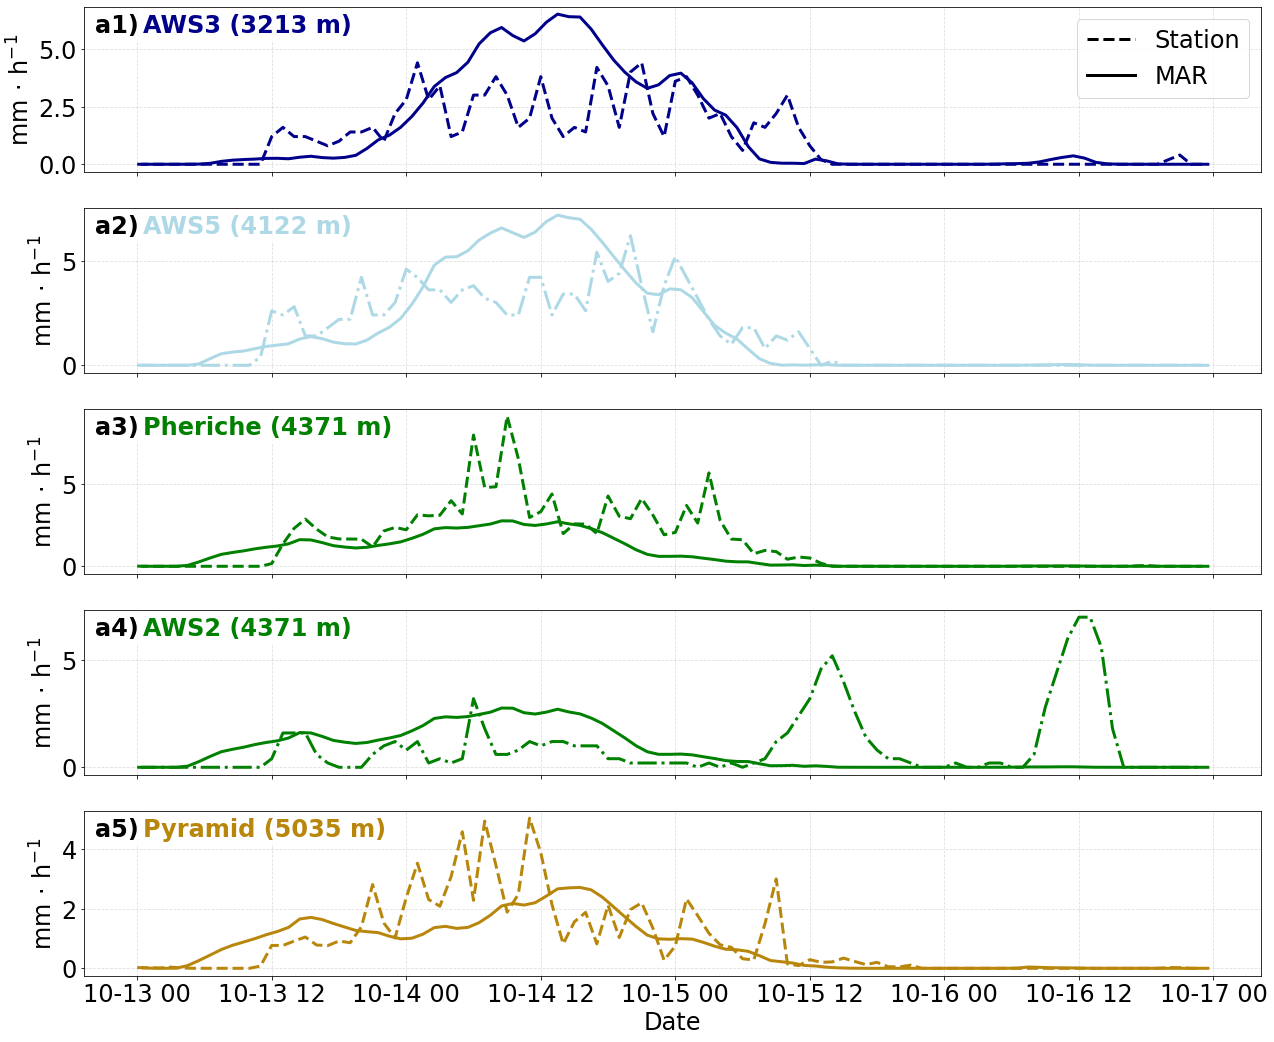

In [47]:
fz=24

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import xarray as xr
import pandas as pd

nsta = len(station_names)

fig, axes = plt.subplots(
    nrows=nsta,
    ncols=1,
    figsize=(18, 3*nsta),
    sharex=True
)

# If only one station
if nsta == 1:
    axes = [axes]

for ax, name in zip(axes, station_names):

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]
    elev = station_elev[name]

    # --------------------------------------------------
    # Observations
    # --------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]

        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):

        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # --------------------------------------------------
    # Model
    # --------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    # --------------------------------------------------
    # Plot obs
    # --------------------------------------------------
    ax.plot(
        x_obs,
        y_obs,
        color=color,
        lw=3,
        linestyle=obs_ls,
        label="Observation"
    )

    # --------------------------------------------------
    # Plot MAR
    # --------------------------------------------------
    ax.plot(
        model_event.time,
        model_event.values,
        #color="black",
        color=color,
        lw=3,
        linestyle="-",
        label="MAR"
    )

    # --------------------------------------------------
    ax.set_ylabel(r"$\mathrm{mm}\,\cdot\,\mathrm{h}^{-1}$" , fontsize=fz)

    panel = f"a{station_names.index(name)+1})"

    ax.text(
    0.01, 0.96,
    panel,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=fz,
    fontweight="bold",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )

# Station name + elevation
    ax.text(
    0.05, 0.96,
    f"{name} ({elev} m)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=fz,
    fontweight="bold",
    color=color,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.4
    )

    from matplotlib.lines import Line2D

handles = [
Line2D([], [], color='black', lw=3, linestyle=obs_ls,
               #label=f"{name} ({elev} m)"),
           label="Station"),
Line2D([], [], color='black', lw=3, linestyle="-",
           label="MAR")
]

axes[0].legend(
    handles=handles,
    fontsize=fz,
    loc="upper right"
    )

# Only bottom panel gets x-label
axes[-1].set_xlabel(
    "Date",
    fontsize=fz
)



plt.rcParams.update({
    "font.size": fz,
    "axes.labelsize": fz,
    "axes.titlesize": fz,
    "xtick.labelsize": fz,
    "ytick.labelsize": fz,
    "legend.fontsize": fz,
    "figure.titlesize": fz,
})

plotname = (
    f"FIG12_col{letter}_pre_hourly_event_"
    f"{idate_event}-{fdate_event}_all_stations_rev1_awsremoved_fz"
)

plt.tight_layout()
#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


In [ ]:
print(fz)

Saved: /home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/figures_MAR_HMA_evaluation_paper/FIG12_cola_pre_cumsum_event_2013-10-13-2013-10-16_all_stations_rev1_awsremoved.png


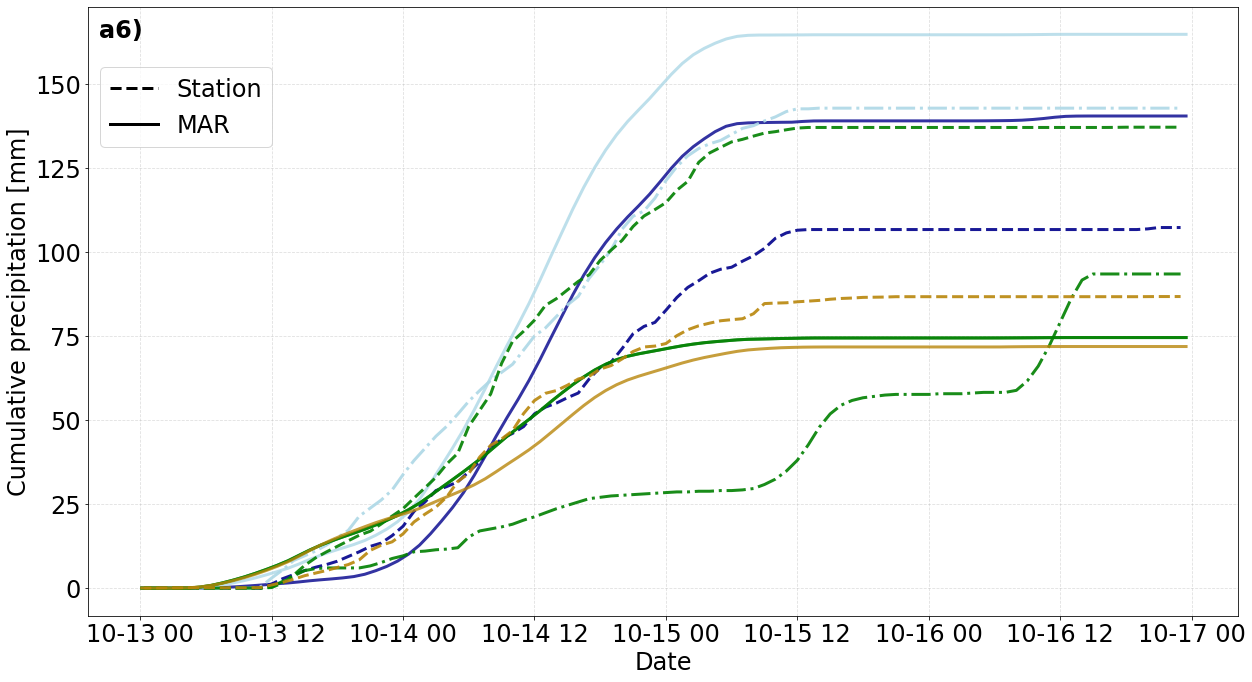

In [48]:

# ==========================================================
# Figure
# ==========================================================
fig, ax = plt.subplots(figsize=(18, 10))

lw_obs = 3
lw_mod = 3

# ==========================================================
for name in station_names:

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]

    # ------------------------------------------------------
    # Convert observations to common format
    # ------------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]

        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):

        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # ------------------------------------------------------
    # Cumulative observations
    # ------------------------------------------------------
    y_obs_cumsum = np.nancumsum(y_obs)

    # ------------------------------------------------------
    # Model data
    # ------------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    y_mod_cumsum = np.nancumsum(model_event.values)

    # ------------------------------------------------------
    # Plot cumulative observations
    # ------------------------------------------------------
    ax.plot(
        x_obs,
        y_obs_cumsum,
        color=color,
        lw=lw_obs,
        linestyle=obs_ls,
        alpha=0.9
    )

    # ------------------------------------------------------
    # Plot cumulative MAR model
    # ------------------------------------------------------
    ax.plot(
        model_event.time,
        y_mod_cumsum,
        color=color,
        lw=lw_mod,
        linestyle='-',
        alpha=0.8
    )

# ==========================================================
# Labels
# ==========================================================
ax.set_xlabel(
    "Date",
    fontsize=fz
)

ax.set_ylabel(
    "Cumulative precipitation [mm]",
    fontsize=fz
)

ax.grid(
    True,
    linestyle='--',
    alpha=0.4
)

ax.tick_params(
    axis='both',
    labelsize=fz
    )

# ==========================================================
# Legend
# ==========================================================
'''
legend_elements = []

for name in station_names:

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]
    elev = station_elev[name]

    legend_elements.append(
        Line2D(
            [0], [0],
            color=color,
            lw=3,
            linestyle=obs_ls,
            label=f"{name} ({elev} m)"
        )
    )

# ==========================================================
# MAR example
# ==========================================================
legend_elements.append(
    Line2D(
        [0], [0],
        color='black',
        lw=3,
        linestyle='-',
        label='MAR in station'
    )
)

ax.legend(
    handles=legend_elements,
    fontsize=14,
    frameon=True,
    loc='upper left',
    ncol=1
)
'''
# ==========================================================
# Panel label
# ==========================================================
ax.text(
    0.01, 0.98,
    f"{letter}{number})",
    transform=ax.transAxes,
    fontsize=fz,
    fontweight='bold',
    va='top',
    ha='left'
)

plt.rcParams.update({
    "font.size": fz,
    "axes.labelsize":fz,
    "axes.titlesize": fz,
    "xtick.labelsize": fz,
    "ytick.labelsize": fz,
    "legend.fontsize": fz,
    "figure.titlesize": fz,
})

from matplotlib.lines import Line2D

handles = [
    Line2D([], [], color='black', lw=3, linestyle=obs_ls,
               #label=f"{name} ({elev} m)"),
           label="Station"),
    Line2D([], [], color='black', lw=3, linestyle="-",
           label="MAR")
    ]

ax.legend(
    handles=handles,
    fontsize=fz,
    loc="upper left",
    bbox_to_anchor=(0.0, 0.92)   # baja la leyenda
)

# ==========================================================
# Save figure
# ==========================================================
plt.tight_layout()

plotname = (
    f"FIG12_cola_pre_cumsum_event_"
    f"{idate_event}-{fdate_event}_all_stations_rev1_awsremoved"
)


#plt.savefig(
#    f"{plotsDir}{plotname}.png",
#    bbox_inches="tight",
#    dpi=300
#)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()

In [49]:
print(fz)

24


In [50]:
#fz=

# ==========================================================
letter='b'
idate_event = "2014-10-13"
fdate_event = "2014-10-15"

station_styles = {
    "AWS3":       {"color": "darkblue",        "obs_ls": "--"},
   # "Phortse":    {"color": "blue",         "obs_ls": "--"},
    "AWS5":       {"color": "lightblue",        "obs_ls": "-."},
    "Pheriche":   {"color": "green",         "obs_ls": "--"},
   # "AWS2":       {"color": "green",         "obs_ls": "-."},
   # "Khare":      {"color": "orange",           "obs_ls": "--"},
    "Pyramid":    {"color": "darkgoldenrod",          "obs_ls": "--"},
    #"AWS0":       {"color": "darkgoldenrod",          "obs_ls": "-."},
  #  "AWS1":       {"color": "darkgoldenrod",          "obs_ls": ":"},
   # "Base Camp":  {"color": "brown", "obs_ls": "--"},
 #   "AWS4":       {"color": "brown",    "obs_ls": "--"},
}
station_names = list(station_styles.keys())
number='5'

Saved: /home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/figures_MAR_HMA_evaluation_paper/FIG12_colb_pre_hourly_event_2014-10-13-2014-10-15_all_stations_rev1_awsremoved.png


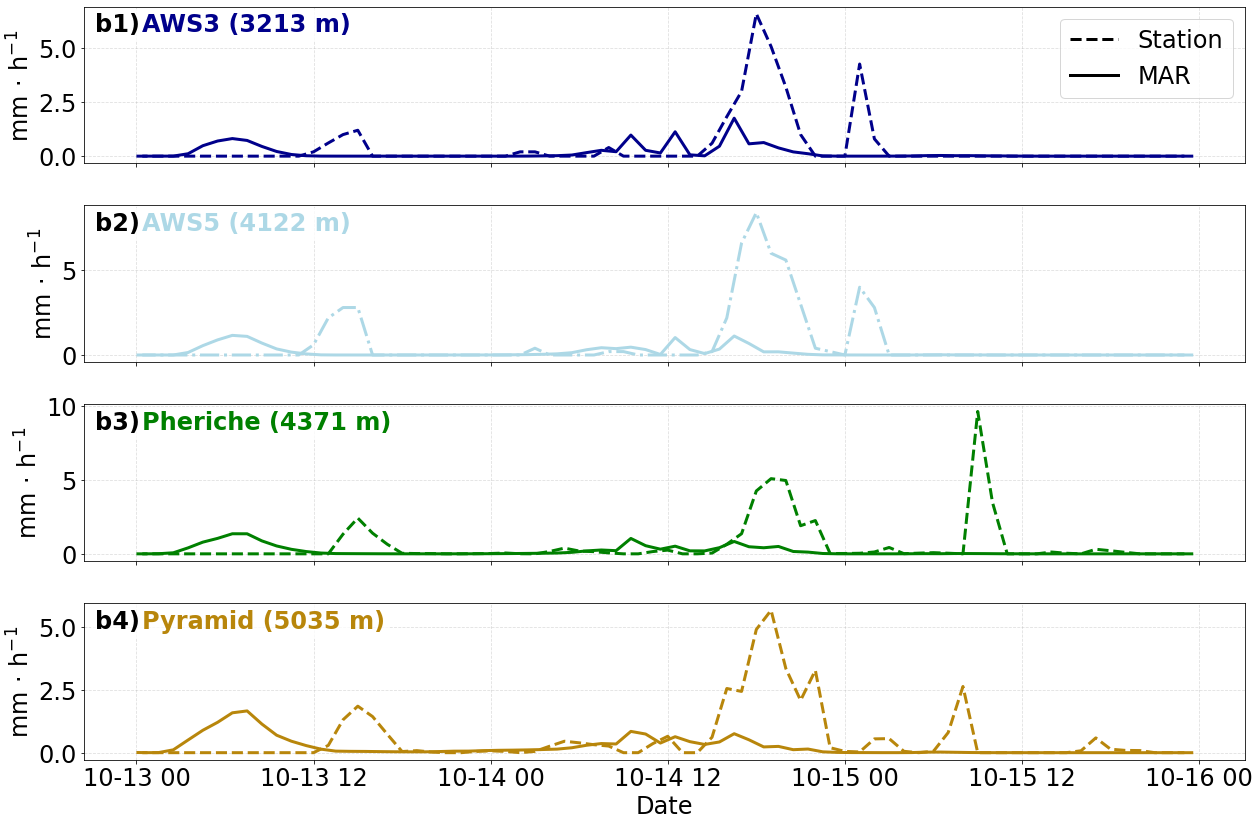

In [51]:


nsta = len(station_names)

fig, axes = plt.subplots(
    nrows=nsta,
    ncols=1,
    figsize=(18, 3*nsta),
    sharex=True
)

# If only one station
if nsta == 1:
    axes = [axes]

for ax, name in zip(axes, station_names):

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]
    elev = station_elev[name]

    # --------------------------------------------------
    # Observations
    # --------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]

        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):

        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # --------------------------------------------------
    # Model
    # --------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    # --------------------------------------------------
    # Plot obs
    # --------------------------------------------------
    ax.plot(
        x_obs,
        y_obs,
        color=color,
        lw=3,
        linestyle=obs_ls,
        label="Observation"
    )

    # --------------------------------------------------
    # Plot MAR
    # --------------------------------------------------
    ax.plot(
        model_event.time,
        model_event.values,
        color=color,#"black",
        lw=3,
        linestyle="-",
        label="MAR"
    )

    # --------------------------------------------------
    ax.set_ylabel(r"$\mathrm{mm}\,\cdot\,\mathrm{h}^{-1}$", fontsize=fz)

    panel = f"{letter}{station_names.index(name)+1})"

    ax.text(
    0.01, 0.96,
    panel,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=fz,
    fontweight="bold",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )

# Station name + elevation
    ax.text(
    0.05, 0.96,
    f"{name} ({elev} m)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=fz,
    fontweight="bold",
    color=color,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.4
    )

    from matplotlib.lines import Line2D

handles = [
Line2D([], [], color='black', lw=3, linestyle=obs_ls,
               #label=f"{name} ({elev} m)"),
           label="Station"),
Line2D([], [], color='black', lw=3, linestyle="-",
           label="MAR")
]

axes[0].legend(
    handles=handles,
    fontsize=fz,
    loc="upper right"
    )
# Only bottom panel gets x-label
axes[-1].set_xlabel(
    "Date",
    fontsize=fz
)


plt.rcParams.update({
    "font.size": fz,
    "axes.labelsize": fz,
    "axes.titlesize": fz,
    "xtick.labelsize": fz,
    "ytick.labelsize": fz,
    "legend.fontsize": fz,
    "figure.titlesize": fz,
})

plotname = (
    f"FIG12_col{letter}_pre_hourly_event_"
    f"{idate_event}-{fdate_event}_all_stations_rev1_awsremoved"
)

plt.tight_layout()
#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


Saved: /home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/figures_MAR_HMA_evaluation_paper/FIG12_colb_pre_cumsum_event_2014-10-13-2014-10-15_all_stations_rev1_awsremoved.png


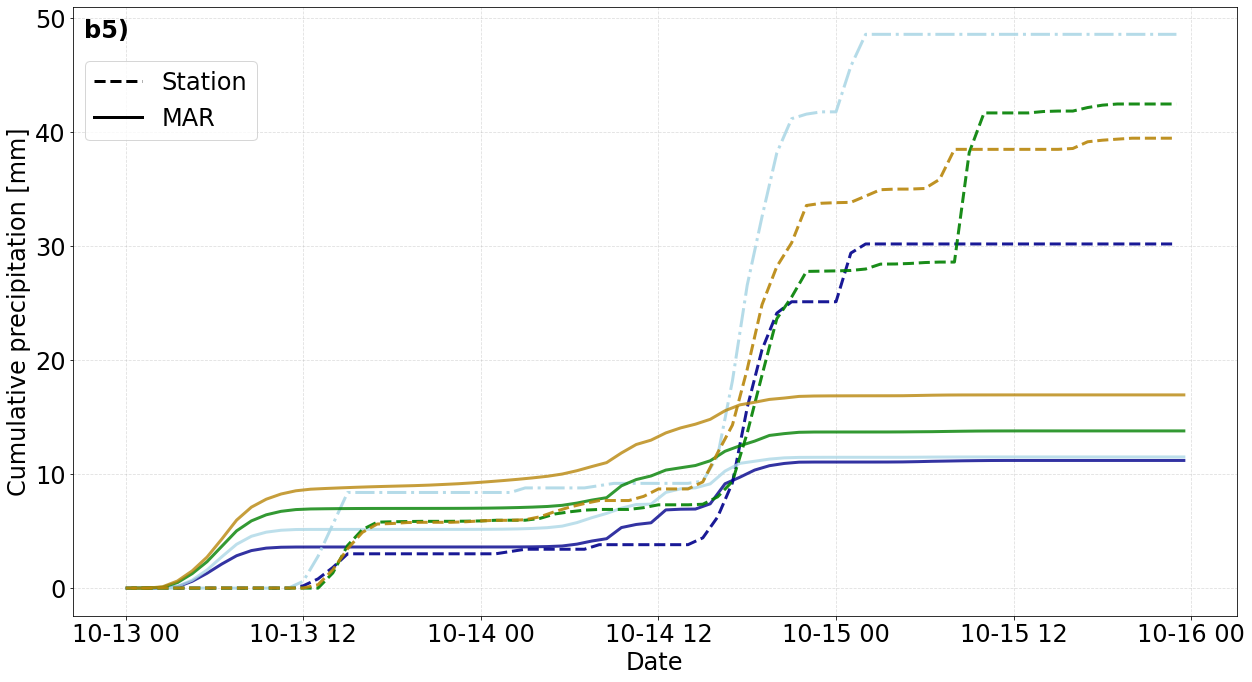

In [52]:

# ==========================================================
# Figure
# ==========================================================
fig, ax = plt.subplots(figsize=(18, 10))

lw_obs = 3
lw_mod = 3

# ==========================================================
for name in station_names:

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]

    # ------------------------------------------------------
    # Convert observations to common format
    # ------------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]

        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):

        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # ------------------------------------------------------
    # Cumulative observations
    # ------------------------------------------------------
    y_obs_cumsum = np.nancumsum(y_obs)

    # ------------------------------------------------------
    # Model data
    # ------------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    y_mod_cumsum = np.nancumsum(model_event.values)

    # ------------------------------------------------------
    # Plot cumulative observations
    # ------------------------------------------------------
    ax.plot(
        x_obs,
        y_obs_cumsum,
        color=color,
        lw=lw_obs,
        linestyle=obs_ls,
        alpha=0.9
    )

    # ------------------------------------------------------
    # Plot cumulative MAR model
    # ------------------------------------------------------
    ax.plot(
        model_event.time,
        y_mod_cumsum,
        color=color,
        lw=lw_mod,
        linestyle='-',
        alpha=0.8
    )

# ==========================================================
# Labels
# ==========================================================
ax.set_xlabel(
    "Date",
    fontsize=fz
)

ax.set_ylabel(
    "Cumulative precipitation [mm]",
    fontsize=fz
)

ax.grid(
    True,
    linestyle='--',
    alpha=0.4
)

ax.tick_params(
    axis='both',
    labelsize=fz
)

# ==========================================================
# Panel label
# ==========================================================
ax.text(
    0.01, 0.98,
    f"{letter}{number})",
    transform=ax.transAxes,
    fontsize=fz,
    fontweight='bold',
    va='top',
    ha='left'
)

plt.rcParams.update({
    "font.size": fz,
    "axes.labelsize": fz,
    "axes.titlesize": fz,
    "xtick.labelsize": fz,
    "ytick.labelsize": fz,
    "legend.fontsize": fz,
    "figure.titlesize": fz,
})

from matplotlib.lines import Line2D

handles = [
    Line2D([], [], color='black', lw=3, linestyle=obs_ls,
               #label=f"{name} ({elev} m)"),
           label="Station"),
    Line2D([], [], color='black', lw=3, linestyle="-",
           label="MAR")
    ]

ax.legend(
    handles=handles,
    fontsize=fz,
    loc="upper left",
    bbox_to_anchor=(0.0, 0.93)   # baja la leyenda
)

# ==========================================================
# Save figure
# ==========================================================
plt.tight_layout()

plotname = (
    f"FIG12_col{letter}_pre_cumsum_event_"
    f"{idate_event}-{fdate_event}_all_stations_rev1_awsremoved"
)

#plt.savefig(
#    f"{plotsDir}{plotname}.png",
#    bbox_inches="tight",
#    dpi=300
#)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()

In [53]:
print(fz)

24


In [54]:
print(plotsDir)

/home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/figures_MAR_HMA_evaluation_paper/


In [55]:
letter='c'
idate_event = "2021-10-17"
fdate_event = "2021-10-21"

station_styles = {
   # "AWS3":       {"color": "darkblue",        "obs_ls": "--"},
    "Phortse":    {"color": "blue",         "obs_ls": "--"},
    #"AWS5":       {"color": "lightblue",        "obs_ls": "-."},
    "Pheriche":   {"color": "green",         "obs_ls": "--"},
    "AWS2":       {"color": "green",         "obs_ls": "-."},
    
    "Pyramid":    {"color": "darkgoldenrod",          "obs_ls": "--"},
    #"AWS0":       {"color": "darkgoldenrod",          "obs_ls": "-."},
    "AWS1":       {"color": "darkgoldenrod",          "obs_ls": ":"},
    "Khare":      {"color": "orange",           "obs_ls": "--"},
    "Base Camp":  {"color": "brown", "obs_ls": "-."},
  #  "AWS4":       {"color": "brown",    "obs_ls": "--"},
}
station_names = list(station_styles.keys())
number='8'

Saved: /home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/figures_MAR_HMA_evaluation_paper/FIG12_colc_pre_hourly_event_2021-10-17-2021-10-21_all_stations_rev1_awsremoved.png


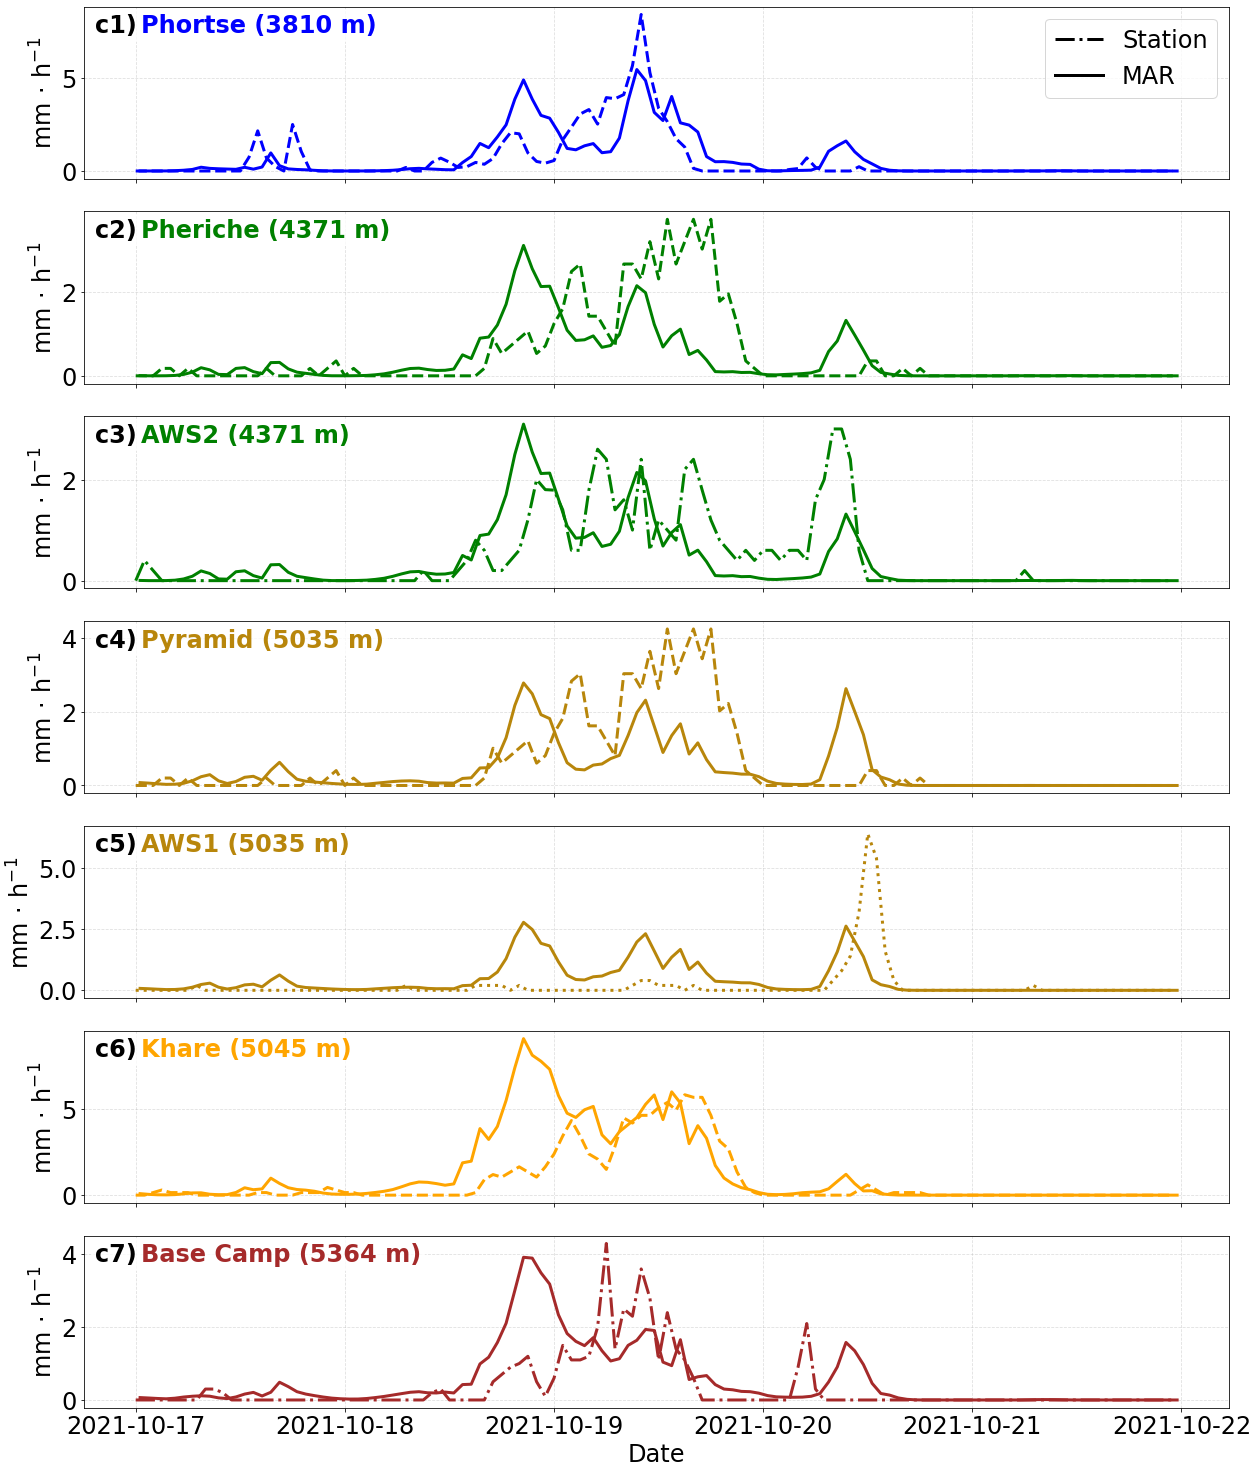

In [56]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import xarray as xr
import pandas as pd

nsta = len(station_names)

fig, axes = plt.subplots(
    nrows=nsta,
    ncols=1,
    figsize=(18, 3*nsta),
    sharex=True
)

# If only one station
if nsta == 1:
    axes = [axes]

for ax, name in zip(axes, station_names):

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]
    elev = station_elev[name]

    # --------------------------------------------------
    # Observations
    # --------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]

        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):

        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # --------------------------------------------------
    # Model
    # --------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    # --------------------------------------------------
    # Plot obs
    # --------------------------------------------------
    ax.plot(
        x_obs,
        y_obs,
        color=color,
        lw=3,
        linestyle=obs_ls,
        label="Observation"
    )

    # --------------------------------------------------
    # Plot MAR
    # --------------------------------------------------
    ax.plot(
        model_event.time,
        model_event.values,
        color=color,#"black",
        lw=3,
        linestyle="-",
        label="MAR"
    )

    # --------------------------------------------------
    ax.set_ylabel(r"$\mathrm{mm}\,\cdot\,\mathrm{h}^{-1}$", fontsize=fz)

    panel = f"{letter}{station_names.index(name)+1})"

    ax.text(
    0.01, 0.96,
    panel,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=fz,
    fontweight="bold",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )

# Station name + elevation
    ax.text(
    0.05, 0.96,
    f"{name} ({elev} m)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=fz,
    fontweight="bold",
    color=color,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.4
    )

    from matplotlib.lines import Line2D

handles = [
Line2D([], [], color='black', lw=3, linestyle=obs_ls,
               #label=f"{name} ({elev} m)"),
           label="Station"),
Line2D([], [], color='black', lw=3, linestyle="-",
           label="MAR")
]

axes[0].legend(
    handles=handles,
    fontsize=fz,
    loc="upper right"
    )
# Only bottom panel gets x-label
axes[-1].set_xlabel(
    "Date",
    fontsize=fz
)

plt.tight_layout()

plt.rcParams.update({
    "font.size": fz,
    "axes.labelsize": fz,
    "axes.titlesize": fz,
    "xtick.labelsize": fz,
    "ytick.labelsize": fz,
    "legend.fontsize": fz,
    "figure.titlesize": fz,
})

plotname = (
    f"FIG12_col{letter}_pre_hourly_event_"
    f"{idate_event}-{fdate_event}_all_stations_rev1_awsremoved"
)

plt.tight_layout()
#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


Saved: /home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/figures_MAR_HMA_evaluation_paper/FIG12_colc_pre_cumsum_event_2021-10-17-2021-10-21_all_stations_rev1_awsremoved.png


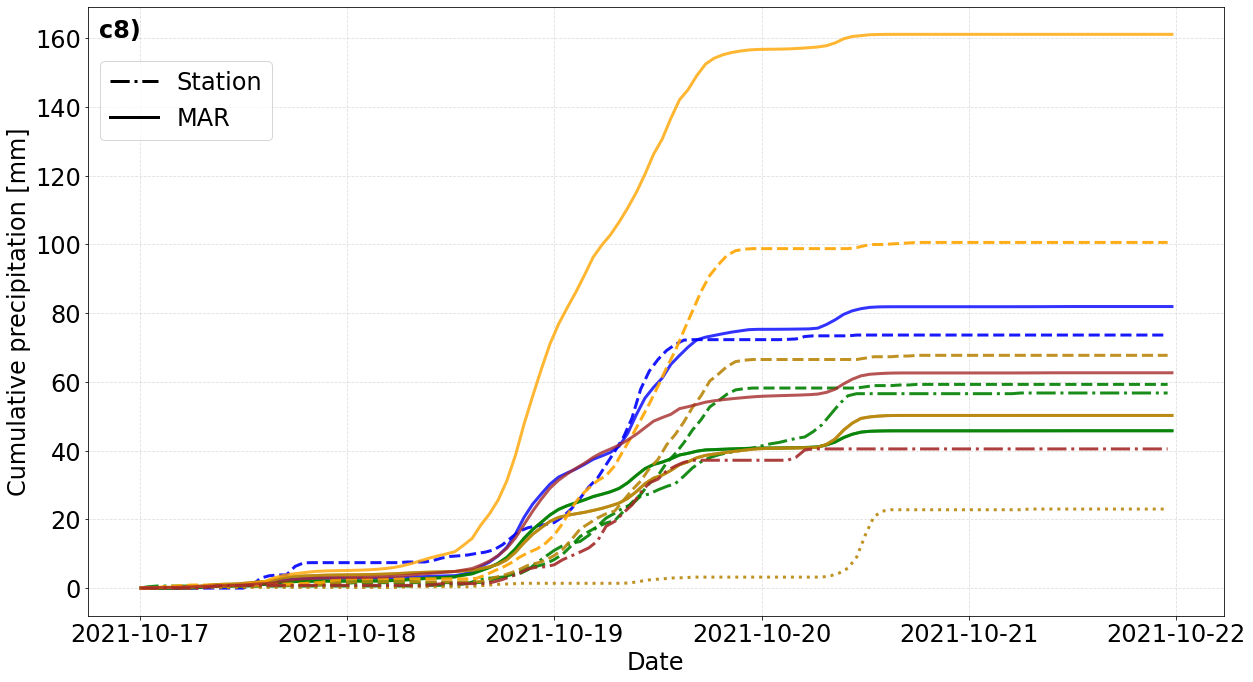

In [57]:

# ==========================================================
# Figure
# ==========================================================
fig, ax = plt.subplots(figsize=(18, 10))

lw_obs = 3
lw_mod = 3

# ==========================================================
for name in station_names:

    obs = stations_rr_hourly_all[name]
    model = ts_TF_model_all[name]

    color = station_styles[name]["color"]
    obs_ls = station_styles[name]["obs_ls"]

    # ------------------------------------------------------
    # Convert observations to common format
    # ------------------------------------------------------
    if isinstance(obs, xr.Dataset):

        varname = list(obs.data_vars)[0]

        obs_event = obs[varname].sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, xr.DataArray):

        obs_event = obs.sel(
            time=slice(idate_event, fdate_event)
        )

        x_obs = obs_event.time.values
        y_obs = obs_event.values

    elif isinstance(obs, pd.Series):

        obs_event = obs.loc[idate_event:fdate_event]

        x_obs = obs_event.index
        y_obs = obs_event.values

    else:
        raise TypeError(
            f"Unsupported type for station {name}: {type(obs)}"
        )

    # ------------------------------------------------------
    # Cumulative observations
    # ------------------------------------------------------
    y_obs_cumsum = np.nancumsum(y_obs)

    # ------------------------------------------------------
    # Model data
    # ------------------------------------------------------
    model_event = model.sel(
        time=slice(idate_event, fdate_event)
    )

    y_mod_cumsum = np.nancumsum(model_event.values)

    # ------------------------------------------------------
    # Plot cumulative observations
    # ------------------------------------------------------
    ax.plot(
        x_obs,
        y_obs_cumsum,
        color=color,
        lw=lw_obs,
        linestyle=obs_ls,
        alpha=0.9
    )

    # ------------------------------------------------------
    # Plot cumulative MAR model
    # ------------------------------------------------------
    ax.plot(
        model_event.time,
        y_mod_cumsum,
        color=color,
        lw=lw_mod,
        linestyle='-',
        alpha=0.8
    )

# ==========================================================
# Labels
# ==========================================================
ax.set_xlabel(
    "Date",
    fontsize=fz
)

ax.set_ylabel(
    "Cumulative precipitation [mm]",
    fontsize=fz
)

ax.grid(
    True,
    linestyle='--',
    alpha=0.4
)

ax.tick_params(
    axis='both',
    labelsize=fz
)

# ==========================================================
# Panel label
# ==========================================================
ax.text(
    0.01, 0.98,
    f"{letter}{number})",
    transform=ax.transAxes,
    fontsize=fz,
    fontweight='bold',
    va='top',
    ha='left'
)

plt.rcParams.update({
    "font.size": fz,
    "axes.labelsize": fz,
    "axes.titlesize": fz,
    "xtick.labelsize": fz,
    "ytick.labelsize": fz,
    "legend.fontsize": fz,
    "figure.titlesize": fz,
})

from matplotlib.lines import Line2D

handles = [
    Line2D([], [], color='black', lw=3, linestyle=obs_ls,
               #label=f"{name} ({elev} m)"),
           label="Station"),
    Line2D([], [], color='black', lw=3, linestyle="-",
           label="MAR")
    ]

ax.legend(
    handles=handles,
    fontsize=fz,
    loc="upper left",
    bbox_to_anchor=(0.0, 0.93)   # baja la leyenda
)

# ==========================================================
# Save figure
# ==========================================================
plt.tight_layout()

plotname = (
    f"FIG12_col{letter}_pre_cumsum_event_"
    f"{idate_event}-{fdate_event}_all_stations_rev1_awsremoved"
)


#plt.savefig(
#    f"{plotsDir}{plotname}.png",
#    bbox_inches="tight",
#    dpi=300
#)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()